# Prototipo Pythia-70m — IIC103G

Clona el repo `iic103g-pythia-prototipo` y corre el pipeline mini para medir factibilidad.

**Antes de correr:** pon tu usuario de GitHub en `GH_USER` (celda siguiente).

Recomendado: `Runtime -> Change runtime type -> GPU (T4 o L4)`.

In [1]:
GH_USER  = "igufu"  # <-- editar
REPO_URL = f"https://github.com/{GH_USER}/iic103g-pythia-prototipo.git"
import os, subprocess, pathlib
if not pathlib.Path("repo").exists():
    subprocess.run(["git", "clone", "--depth", "1", REPO_URL, "repo"], check=True)
os.chdir("repo")
print("cwd:", os.getcwd())
print("contenido:", os.listdir())

cwd: /content/repo
contenido: ['.git', 'datos', 'scripts', 'requirements.txt', 'colab.ipynb', '.gitignore', 'graficos']


In [2]:
!pip install -q "transformer_lens>=2.0,<4.0" "transformers>=4.40,<5.0"
!pip install -q -r requirements.txt
# Verificacion rapida: la clase HookedTransformer existe en TL < 4
import importlib, transformer_lens
importlib.reload(transformer_lens)
from transformer_lens import HookedTransformer
print("HookedTransformer OK")

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio-client 2.7.2 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
diffusers 0.42.1 requires huggingface-hub<3.0,>=1.32.0, but you have huggingface-hub 0.36.2 which is incompatible.
gradio 6.31.0 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
HookedTransformer OK


In [3]:
import torch
print("CUDA disponible:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("Device:", torch.cuda.get_device_name(0))
# 1. tests unitarios de logica pura (rapidos, sin red ni GPU)
!python scripts/test_logica.py
# 2. smoke test del entorno real (carga el modelo y chequea API)
!python scripts/00_smoke.py

CUDA disponible: True
Device: Tesla T4
  [OK]   test_topk_indexado_excluye_bos
  [OK]   test_topk_son_los_maximos_reales
  [OK]   test_entropia_shannon_casos_borde
  [OK]   test_kurtosis_normal_cerca_de_cero
  [OK]   test_posiciones_son_1_a_128_despues_de_bos

5/5 tests OK

== 1. imports ==
I0000 00:00:1794616700.813784     739 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
  [OK]   torch 2.14.1+cu130  numpy 2.4.6  pandas 2.2.3
  [OK]   scipy 1.16.3  matplotlib 3.10.0
  [OK]   transformers 4.57.6  datasets 4.8.5
  [FAIL] imports basicos
         AttributeError: module 'transformer_lens' has no attribute '__version__'

== 2. API TransformerLens: HookedTransformer existe ==
  [OK]   HookedTransformer importable (TL < 4.0)

== 3. cargar pythia-70m checkpoint 1000 + forward con cache ==
config.json: 100% 567/567 [00:00<00:00, 3.27MB/s]
model.safetensors: 100% 282M/282M [00:02<00:00, 107MB/s]
tokenizer_config.json: 100% 396/396 [00:00<00:00, 2.00MB/s]


In [4]:
!python scripts/01_dataset.py

data/train-00000-of-00001-4746b8785c874c(…): 100% 33.3M/33.3M [00:00<00:00, 40.1MB/s]
Generating train split: 100% 10000/10000 [00:00<00:00, 38915.24 examples/s]
[01] Guardados 200 docs en /content/repo/datos/dataset.parquet
[01] 15 fuentes distintas en el subset


In [5]:
!python scripts/02_extraer.py

I0000 00:00:1794616742.857478     992 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
[02] device=cuda dtype=torch.float32

[02] === checkpoint 0 ===
model.safetensors: 100% 282M/282M [00:04<00:00, 68.7MB/s]
Loaded pretrained model pythia-70m into HookedTransformer
Moving model to device:  cuda
[02] ckpt=0  tiempo=16.3s  RSS=2358MB  filas=245760

[02] === checkpoint 1000 ===
Loaded pretrained model pythia-70m into HookedTransformer
Moving model to device:  cuda
[02] ckpt=1000  tiempo=11.7s  RSS=2487MB  filas=245760

[02] === checkpoint 143000 ===
model.safetensors: 100% 282M/282M [00:02<00:00, 117MB/s]
Loaded pretrained model pythia-70m into HookedTransformer
Moving model to device:  cuda
[02] ckpt=143000  tiempo=14.7s  RSS=2534MB  filas=245760

[02] CSV: /content/repo/datos/activaciones.csv  (71.7 MB, 737280 filas)
[02] stats: /content/repo/datos/stats.json


In [6]:
!python scripts/contar.py

737280 filas x 12 columnas
columnas: ['step', 'capa', 'neurona', 'rank', 'activacion', 'token_id', 'token_texto', 'doc_id', 'posicion', 'contexto_izq', 'contexto_der', 'fuente_pile']


In [7]:
!python scripts/03_metricas.py

[03] Metricas: 36864 filas en /content/repo/datos/metricas.csv
[03] entropia_fuente  min=-0.000  max=3.441
[03] kurtosis  min=-1.27  max=9703.61


In [8]:
!python scripts/04_tests.py

[04] n=12288
{
  "n": 12288,
  "comparacion": "step 1000 vs step 143000",
  "wilcoxon": {
    "stat": 31711344.0,
    "p": 4.3908324264338785e-49
  },
  "spearman": {
    "rho": 0.174538309585455,
    "p": 1.1954732150636404e-84
  }
}


In [9]:
!python scripts/05_graficos.py

[05] Guardados /content/repo/graficos/lineas_entropia.png y /content/repo/graficos/scatter_entropia.png


In [10]:
!python scripts/06_factibilidad.py

[06] Escrito /content/repo/FACTIBILIDAD.md


In [11]:
!python scripts/07_verificar.py

Chain of verification:
  [OK  ] 1. filas CSV == n_ckpt * n_layers * d_mlp * 20
         esperado: 737280
         obtenido: 737280
  [OK  ] 2. columnas en orden esperado
         esperado: ['step', 'capa', 'neurona', 'rank', 'activacion', 'token_id', 'token_texto', 'doc_id', 'posicion', 'contexto_izq', 'contexto_der', 'fuente_pile']
         obtenido: ['step', 'capa', 'neurona', 'rank', 'activacion', 'token_id', 'token_texto', 'doc_id', 'posicion', 'contexto_izq', 'contexto_der', 'fuente_pile']
  [OK  ] 3. cada (step,capa,neurona) tiene 20 filas
         esperado: True
         obtenido: True
  [OK  ] 4. ninguna fila con posicion==0
         esperado: True
         obtenido: True
  [OK  ] 5. entropia en [0, log2(15)=3.907]
         esperado: True
         obtenido: True
Todos los chequeos pasaron.


## Resultados

In [12]:
from IPython.display import Markdown, Image, display
display(Markdown(open('FACTIBILIDAD.md').read()))

# FACTIBILIDAD — Prototipo Pythia-70m (IIC103G)

- Dispositivo: `cuda`  dtype: `torch.float32`
- Docs: 200 de pile-10k (>= 128 tokens, 31 descartados)
- Fuentes pile unicas en el subset: 15
- Checkpoints procesados: [0, 1000, 143000]
- Capas detectadas: 6  neuronas MLP: 2048

## SUPUESTOS

- `fuente_pile` = `meta.pile_set_name` del dataset NeelNanda/pile-10k.
- Cada secuencia lleva BOS prependido => 129 tokens; posicion 0 = BOS y se excluye del top-k.
- Kurtosis se calcula sobre los 200x129 = 25800 tokens (incluye BOS) porque el encargo pide 'todos los tokens'.
- Contexto izq/der: 5 tokens decodificados a cada lado.
- fp16 cuando hay GPU, fp32 en CPU.
- Un unico CSV `activaciones.csv` para los 3 checkpoints.

## Tiempos y tamanio por checkpoint

| checkpoint | segundos | MB CSV (prorrateado) | filas | RSS (MB) |
|---:|---:|---:|---:|---:|
| 0 | 16.3 | 23.89 | 245760 | 2358 |
| 1000 | 11.7 | 23.89 | 245760 | 2487 |
| 143000 | 14.7 | 23.89 | 245760 | 2534 |
| **total** | **42.7** | **71.67** | **737280** |  |

## Proyeccion a 20 checkpoints

Asume que el tiempo escala lineal en #checkpoints (el forward domina) y que 
CSV/filas escalan lineal en k. Para k=50 se agrega 10% extra de tiempo por el top-k y el I/O.

| escenario | tiempo (s) | tiempo (min) | tamanio CSV (MB) | filas |
|---|---:|---:|---:|---:|
| 20 ckpt x k=20 | 285 | 4.7 | 477.8 | 4915200 |
| 20 ckpt x k=50 | 313 | 5.2 | 1194.5 | 12288000 |

## Resultados estadisticos (PRELIMINARES)

Comparacion: step 1000 vs step 143000  n = 12288 neuronas pareadas.
- Wilcoxon pareado: stat = 3.171e+07  p = 4.391e-49
- Spearman: rho = 0.1745  p = 1.195e-84

Son numeros de prototipo (3 checkpoints, 200 docs, top-20). No se interpreta la hipotesis aqui.

## Problemas encontrados

- Ninguno registrado automaticamente durante la ejecucion.

## Recomendacion

- Factible con k=20 (menos de 1 h). k=50 puede ser pesado: recomiendo dejar k=20 o reducir a 10-12 checkpoints en escala logaritmica.


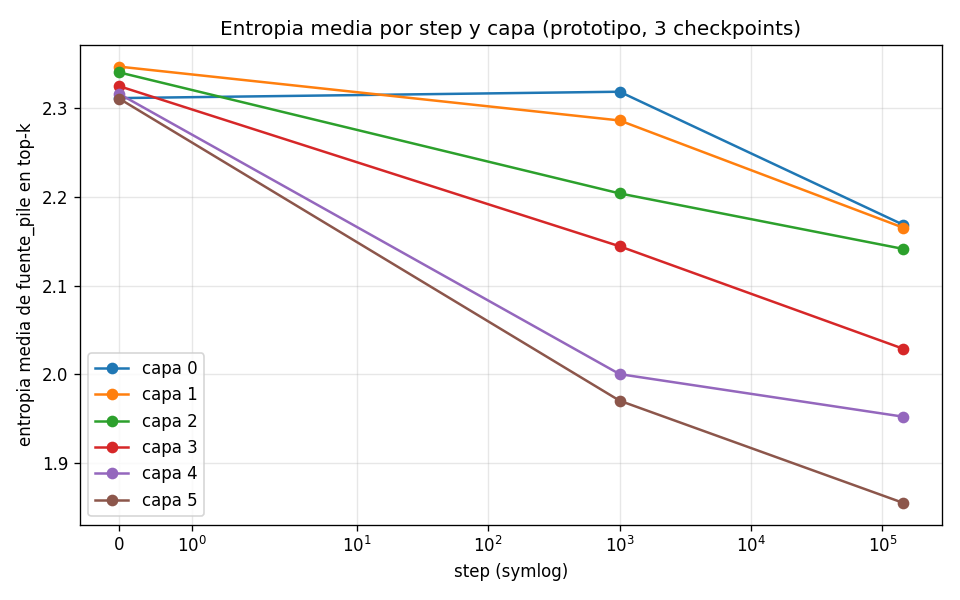

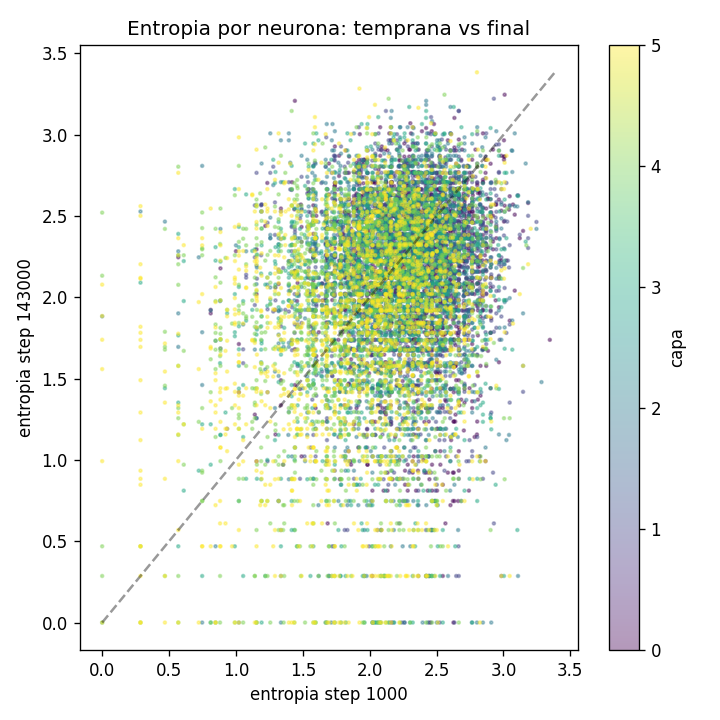

In [13]:
display(Image('graficos/lineas_entropia.png'))
display(Image('graficos/scatter_entropia.png'))

## Descargar artefactos (opcional)

In [14]:
from google.colab import files
files.download('FACTIBILIDAD.md')
files.download('datos/activaciones.csv')
files.download('datos/metricas.csv')
files.download('graficos/lineas_entropia.png')
files.download('graficos/scatter_entropia.png')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>